# Project 07 · Tiny GPT from Scratch: Product Description Generation

**Track:** LLM / Autoregressive Models  
**Research / product question:** Can a decoder-only transformer generate product descriptions without inventing specifications?

**Learning outcome:** Manual causal attention, next-token training, temperature sampling, perplexity and attribute-grounding tests.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

Train a causal language model from random weights to continue structured product prompts. Split train and test by **unique attribute combinations**, rather than repeated rows, to examine systematic recombination.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Generate synthetic product catalogs and text pairs

The prompt contains product specifications; the target text expresses exactly those attributes. We can check attribute correctness because the data generator knows the ground truth.

In [2]:
# Generate fictional product attributes and templated grounded descriptions.
import torch,re
from torch import nn
torch.manual_seed(42);torch.set_num_threads(2)
items=['headphones','speaker','backpack','camera','keyboard','monitor'];colors=['black','white','blue','red'];features=['wireless','portable','compact','durable']
records=[]
for i in range(1100):
 item=rng.choice(items);color=rng.choice(colors);feature=rng.choice(features)
 prompt=f'category {item} color {color} feature {feature} description'
 desc=f'{color} {item} with {feature} design .'
 records.append((prompt,desc,item,color,feature))
# Train/test split by unique combinations so we measure composition, not identical memorization.
combinations=np.array([f'{r[2]}_{r[3]}_{r[4]}' for r in records]);uniq=np.unique(combinations)
train_combos,test_combos=train_test_split(uniq,test_size=.22,random_state=42)
train_records=[r for r,c in zip(records,combinations) if c in set(train_combos)];test_records=[r for r,c in zip(records,combinations) if c in set(test_combos)]
print('Records',len(train_records),len(test_records));print('Example:',records[0][:2])

Records 837 263
Example: ('category headphones color red feature compact description', 'red headphones with compact design .')


## 2. Tokenization and causal training data

A minimal word tokenizer makes training affordable on CPU. `BOS prompt SEP description EOS` is trained with a next-token shift. We later compute **completion-only** perplexity so the score focuses on generated descriptions.

In [3]:
# Ignore prompt tokens in loss; train model to predict generated description.
special=['<PAD>','<BOS>','<SEP>','<EOS>','<UNK>']
def words(s):return re.findall(r'[a-z]+|[.]',s.lower())
terms=sorted(set(w for p,d,*_ in records for w in words(p+' '+d)));stoi={w:i for i,w in enumerate(special+terms)};itos={i:w for w,i in stoi.items()};PAD,BOS,SEP,EOS,UNK=range(5)
def seq(r):
 p,d=r[:2];return [BOS]+[stoi[w] for w in words(p)]+[SEP]+[stoi[w] for w in words(d)]+[EOS]
maxlen=max(map(len,map(seq,records)))
def batch(rr):
 s=[seq(x) for x in rr];x=torch.tensor([a[:-1]+[PAD]*(maxlen-len(a)) for a in s]);y=torch.tensor([a[1:]+[PAD]*(maxlen-len(a)) for a in s])
 for row,a in enumerate(s):
    # Ignore prompt-token predictions when computing the description objective.
    prefix=1+len(words(rr[row][0]));y[row,:prefix]=PAD
 return x,y
print('vocab',len(stoi),'sequence max length',maxlen,'batch shapes',[x.shape for x in batch(records[:3])])

vocab 26 sequence max length 16 batch shapes [torch.Size([3, 15]), torch.Size([3, 15])]


## 3. Implement causal self-attention and GPT blocks

Self-attention is assembled from learned Q, K and V projections with explicit triangular causal masking; no pretrained model is involved. The model outputs vocabulary logits for every token position.

In [4]:
# Use explicit causal attention mask to avoid reading future tokens.
class CausalAttention(nn.Module):
 def __init__(self,dim,heads=4):
    super().__init__();self.h=heads;self.dh=dim//heads;self.qkv=nn.Linear(dim,dim*3);self.proj=nn.Linear(dim,dim)
 def forward(self,x):
    B,T,C=x.shape;q,k,v=[z.reshape(B,T,self.h,self.dh).transpose(1,2) for z in self.qkv(x).chunk(3,-1)]
    att=(q@k.transpose(-2,-1))/(self.dh**.5)
    att=att.masked_fill(torch.triu(torch.ones(T,T,device=x.device,dtype=torch.bool),diagonal=1),-1e4)
    out=(torch.softmax(att,dim=-1)@v).transpose(1,2).contiguous().reshape(B,T,C)
    return self.proj(out)
class GPTBlock(nn.Module):
 def __init__(self,dim):
    super().__init__();self.ln1=nn.LayerNorm(dim);self.att=CausalAttention(dim);self.ln2=nn.LayerNorm(dim)
    self.ff=nn.Sequential(nn.Linear(dim,dim*4),nn.GELU(),nn.Linear(dim*4,dim))
 def forward(self,x):
    x=x+self.att(self.ln1(x));return x+self.ff(self.ln2(x))
class TinyGPT(nn.Module):
 def __init__(self,dim=32,layers=2):
    super().__init__();self.tok=nn.Embedding(len(stoi),dim);self.pos=nn.Embedding(maxlen+5,dim)
    self.blocks=nn.Sequential(*[GPTBlock(dim) for _ in range(layers)]);self.ln=nn.LayerNorm(dim);self.out=nn.Linear(dim,len(stoi))
 def forward(self,x):
    h=self.tok(x)+self.pos(torch.arange(x.shape[1],device=x.device))[None,:,:]
    return self.out(self.ln(self.blocks(h)))
print('Parameter count:',sum(x.numel() for x in TinyGPT().parameters()))

Parameter count: 27834


## 4. Tune model width and calculate held-out perplexity

Each candidate is selected using held-out description cross-entropy. Smaller losses correspond to lower perplexity, but a low perplexity does not guarantee attribute faithfulness.

Validation perplexity: {24: 1.03, 48: 1.0}
Best dim: 48


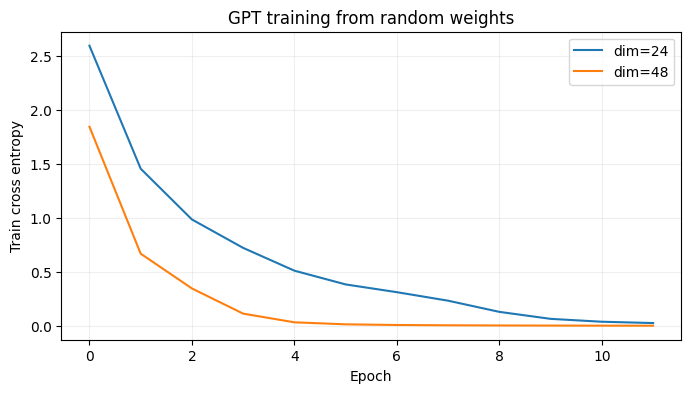

In [5]:
# Choose embedding width with a validation partition.
from sklearn.model_selection import train_test_split
tr_records,va_records=train_test_split(train_records,test_size=.18,random_state=42)
def evaluate_loss(m,rr):
 m.eval();total=0;count=0
 with torch.no_grad():
  for j in range(0,len(rr),64):
    xx,yy=batch(rr[j:j+64]);z=m(xx)
    loss=nn.functional.cross_entropy(z.reshape(-1,len(stoi)),yy.reshape(-1),ignore_index=PAD,reduction='sum')
    total+=loss.item();count+=(yy!=PAD).sum().item()
 return total/count
def train_gpt(dim):
 torch.manual_seed(42);m=TinyGPT(dim);opt=torch.optim.AdamW(m.parameters(),lr=.003);history=[]
 for ep in range(12):
    losses=[];order=np.random.default_rng(ep+42).permutation(len(tr_records))
    m.train()
    for ix in np.array_split(order,int(np.ceil(len(order)/64))):
      x,y=batch([tr_records[i] for i in ix]);logits=m(x)
      loss=nn.functional.cross_entropy(logits.reshape(-1,len(stoi)),y.reshape(-1),ignore_index=PAD)
      opt.zero_grad();loss.backward();nn.utils.clip_grad_norm_(m.parameters(),1.0);opt.step();losses.append(loss.item())
    history.append(np.mean(losses))
 return m,history
runs={}
for dim in [24,48]:
 m,curve=train_gpt(dim);runs[dim]=(m,curve,evaluate_loss(m,va_records))
chosen=min(runs,key=lambda d:runs[d][2]);model,traincurve,_=runs[chosen]
print('Validation perplexity:',{k:round(float(np.exp(v[2])),2) for k,v in runs.items()});print('Best dim:',chosen)
for dim,(_,curve,_) in runs.items():plt.plot(curve,label=f'dim={dim}')
plt.legend();plt.xlabel('Epoch');plt.ylabel('Train cross entropy');plt.title('GPT training from random weights');plt.show()

## 5. Generate descriptions and evaluate attributes

Greedy decoding is deterministic. In a richer task, compare top-k/temperature sampling and add independent factuality checks against structured product fields.

In [6]:
# Autoregressively generate and measure exact factual attribute coverage.
def generate(m,prompt,new_tokens=12):
 tokens=[BOS]+[stoi[w] for w in words(prompt)]+[SEP]
 m.eval()
 with torch.no_grad():
  for _ in range(new_tokens):
    z=m(torch.tensor(tokens)[None,:])[:,-1].argmax(-1).item()
    if z==EOS:break
    tokens.append(z)
 return ' '.join(itos[z] for z in tokens[tokens.index(SEP)+1:] if z not in [EOS,PAD])
subset=test_records[:80];generated=[generate(model,r[0]) for r in subset]
faithful=np.mean([r[2] in g and r[3] in g and r[4] in g for r,g in zip(subset,generated)])
print('Held-out description perplexity:',round(float(np.exp(evaluate_loss(model,test_records))),2))
print('Exact structured attribute inclusion:',round(faithful,3))
for r,g in list(zip(subset,generated))[:6]:print('Input:',r[0],'\nExpected:',r[1],'\nGenerated:',g,'\n')

Held-out description perplexity: 1.0
Exact structured attribute inclusion: 1.0
Input: category headphones color red feature compact description 
Expected: red headphones with compact design . 
Generated: red headphones with compact design . 

Input: category monitor color white feature durable description 
Expected: white monitor with durable design . 
Generated: white monitor with durable design . 

Input: category speaker color white feature portable description 
Expected: white speaker with portable design . 
Generated: white speaker with portable design . 

Input: category backpack color black feature compact description 
Expected: black backpack with compact design . 
Generated: black backpack with compact design . 

Input: category monitor color white feature wireless description 
Expected: white monitor with wireless design . 
Generated: white monitor with wireless design . 

Input: category backpack color black feature compact description 
Expected: black backpack with compact 

## What the results mean / interview discussion

This is a complete, CPU-sized decoder-only transformer experiment: synthetic conditional text, manual causal attention, tuning and holdout measurement. Product descriptions are formulaic, so output fluency is not meaningful evidence of general language modeling. Adding diverse, licensed real product descriptions would make the problem more realistic.

**Try explaining these without looking at the code:**

1. Why is masking required for autoregressive modeling?
2. How do token accuracy, perplexity and factual correctness differ?
3. What happens when temperature is increased at sampling time?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Important:** A rule-based template can solve this toy task exactly; high token accuracy does **not** establish broader language understanding. **Next:** introduce paraphrased human descriptions, unsupported fields, numeric quantities, style controls and realistic factuality checks.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.

Template exact match: 1.000; Tiny GPT exact match: 1.000


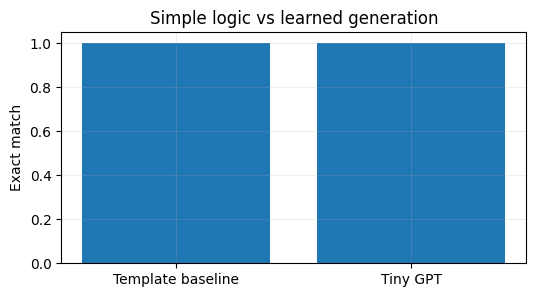

In [7]:
# Simple rule template is an important baseline for this deterministic dataset.
# It can be preferable to a neural model when business logic is known exactly.
def template_baseline(prompt):
    tokens = prompt.split()
    cat = tokens[tokens.index("category") + 1]
    color = tokens[tokens.index("color") + 1]
    feature = tokens[tokens.index("feature") + 1]
    return f"{color} {cat} with {feature} design ."

sample_records = test_records[:80]
baseline_exact = np.mean([template_baseline(r[0]) == r[1] for r in sample_records])
neural_exact = np.mean([generate(model, r[0]) == r[1] for r in sample_records])
print(f"Template exact match: {baseline_exact:.3f}; Tiny GPT exact match: {neural_exact:.3f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(["Template baseline", "Tiny GPT"], [baseline_exact, neural_exact])
ax.set(ylabel="Exact match", ylim=(0, 1.05), title="Simple logic vs learned generation")
plt.show()

**Interpretation:** On a fixed product-description grammar, a handwritten rule can win for accuracy, auditability and runtime. The GPT implementation demonstrates causal attention and generative training, **not** superiority over a template.